# 09 — Parameter Estimation on Lorenz-63

Ported from the mfourdvar *Parameter Estimation* chapter and its
`l63_ode_param_*` development notebooks.

So far the tutorials have treated the dynamical model as *known* and
estimated only the state. Here the model itself has unknown parameters
$\boldsymbol{\theta} = (\sigma, \rho, \beta)$, and we recover them — first on
their own, then jointly with the initial state — from noisy, partial
observations of a few short trajectories.

## From Bayes to a cost function

The generative story has three ingredients. A dynamical model whose
right-hand side depends on $\theta$, an observation model with a mask $m_t$
and Gaussian noise, and prior beliefs about the unknowns:

$$
\begin{aligned}
\text{Dynamics:} \quad & \dot{u} = f(u; \theta), \qquad
  f(u; \theta) = \big(\sigma(u_2 - u_1),\; u_1(\rho - u_3) - u_2,\; u_1 u_2 - \beta u_3\big) \\
\text{Observations:} \quad & y_t = m_t \odot (u_t + \varepsilon_t), \qquad
  \varepsilon_t \sim \mathcal{N}(0, \sigma_{obs}^2 I) \\
\text{Priors:} \quad & u_0 \sim \mathcal{N}(u_b, \sigma_b^2 I), \qquad
  \theta \sim \text{flat}.
\end{aligned}
$$

Because the dynamics are deterministic, the whole trajectory is a function
of the initial state and the parameters through the *flow map*
$\varphi_t(u_0; \theta)$, the solution of the ODE at time $t$:

$$
\varphi_t(u_0; \theta) = u_0 + \int_0^t f\big(\varphi_\tau(u_0; \theta); \theta\big)\, d\tau .
$$

Numerically the flow map is an ODE solver, and any solver builds it by
composing short steps,
$\varphi_{t + \Delta t} = \varphi_{\Delta t} \circ \varphi_t$, which is
what makes the one-step and full-trajectory priors below two views of the
same object.

The posterior over the unknowns given $B$ observed windows is
$p(u_0, \theta \mid y) \propto p(y \mid u_0, \theta)\, p(u_0)\, p(\theta)$,
and taking the negative log turns the Gaussian factors into squared
norms. Up to constants the *maximum a posteriori* estimate minimises

$$
U(u_0, \theta) =
  \underbrace{\frac{1}{2\sigma_{obs}^2} \sum_b \big\| m \odot (\varphi(u_0^b; \theta) - y^b) \big\|^2}_{\text{data misfit}}
+ \underbrace{\frac{1}{2\sigma_b^2} \sum_b \| u_0^b - u_b^b \|^2}_{\text{background}} ,
$$

which is the strong-constraint 4DVar cost of chapter
[6](../06_strong_4dvar.md) with the control variable extended from $u_0$
to $(u_0, \theta)$ — the *augmented state* trick of the data-assimilation
literature. In code it is [`strong_variational_cost`](xref:api#vardax.strong_variational_cost)
with a `forward_fn` that closes over $\theta$. In this sum form the weights
$\alpha_{obs} = 1 / 2\sigma_{obs}^2$ and $\alpha_{bg} = 1 / 2\sigma_b^2$ are
the inverse error variances, and only their *ratio* matters for the
minimiser. One caveat for reading the code: the library's costs are
*means* over their elements (the misfit over $B \cdot T \cdot N$ entries,
the background over $B \cdot N$), so the `alpha` arguments are algorithmic
weights whose variance interpretation carries a factor of $T$ — section 5
does the bookkeeping.

## What the gradient is

Everything below is gradient descent on $U$, so the object that does the
work is the sensitivity of the trajectory to the parameters. By the chain
rule,

$$
\nabla_\theta U = \sum_{t} \Big(\frac{\partial \varphi_t}{\partial \theta}\Big)^{\!\top}
  \frac{\partial \ell_t}{\partial \varphi_t},
\qquad
\ell_t = \frac{1}{2\sigma_{obs}^2}\|m_t \odot (\varphi_t - y_t)\|^2 ,
$$

and the Jacobians $\partial \varphi_t / \partial \theta$ obey their own ODE
(the tangent-linear model). `diffrax` never forms them: the
`RecursiveCheckpointAdjoint` used by [`DynTrajectory`](xref:api#vardax.DynTrajectory)
propagates the residuals backwards through the solve with the adjoint
model, at a memory cost logarithmic in the number of steps. Chapter
[12](../12_adjoint_methods.md) compares this with the continuous adjoint
(`BacksolveAdjoint`) for long windows; with only three parameters
forward-mode sensitivities would be equally cheap here.

The ingredients are the ODE priors from chapter
[19](../19_physical_models.md): a `DynTrajectory` wraps a diffrax solve
around $f(t, u; \theta)$, threads $\theta$ through as the solver `args`, and
lets gradients flow through the integration. In the taxonomy of the
mfourdvar notes this is the *dynamical model* end of the spectrum
($F = F_{\text{dyn}}$ with a handful of physical parameters); replacing
part of $f$ by a neural network gives the *hybrid* models discussed at the
end.

In [1]:
import functools as ft

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import optax

from vardax import Batch1D, DynIncrements, DynTrajectory, strong_variational_cost

## 1. The ODE prior with learnable parameters

The right-hand side reads $\theta$ from the diffrax `args` slot. Anything
passed as `params=` to the prior (or stored as its default `params`) lands
there, so the same object serves fixed-physics and learnable-physics use.
The library's own `Lorenz63` module stores its coefficients as Python
floats, which Equinox's array filter treats as static; for estimation we
want them as an array so that `jax.grad` sees them.

Lorenz-63 is the standard testbed because it is the smallest system with
the property that makes parameter estimation in geophysics hard: chaos.
Its largest Lyapunov exponent is $\lambda_1 \approx 0.9$, so two
trajectories separate by a factor $e$ every $\approx 1.1$ time units. The
windows below are $0.4$ time units long — short enough that the cost in
$(u_0, \theta)$ is smooth and unimodal, long enough to constrain the
parameters. Chapter [6](../06_strong_4dvar.md) discusses what happens to
the strong-constraint cost as the window grows past the Lyapunov time.

In [2]:
THETA_TRUE = jnp.array([10.0, 28.0, 8.0 / 3.0])


def lorenz63_rhs(t, u, theta):
    sigma, rho, beta = theta
    x_, y_, z_ = u
    return jnp.array([sigma * (y_ - x_), x_ * (rho - z_) - y_, x_ * y_ - beta * z_])


# Defaults: Tsit5, adaptive PID controller, RecursiveCheckpointAdjoint.
prior = DynTrajectory(model=lorenz63_rhs, params=THETA_TRUE)

## 2. Generate observed windows

We integrate $B$ short windows from initial conditions drawn *off* the
attractor and observe every other step with Gaussian noise. Gaps are
stored as `NaN` — the convention of real geophysical products — so the
cost is evaluated with `nan_to_num=True` (the mask removes those entries
from the misfit, but $0 \cdot \text{NaN}$ would still poison the gradient).

The off-attractor start matters, and the reason is visible in the
equations. The only place $\sigma$ enters is the term $\sigma (u_2 - u_1)$,
so the sensitivity of the trajectory to $\sigma$ is driven by
$\int (u_2 - u_1)\, d\tau$. On the attractor the first two components
track each other closely most of the time, that integral stays small, and
$\sigma$ is nearly invisible from short windows: the cost is flat in
$\sigma$ to within the noise floor. Starting away from the attractor
produces a transient during which $u_1 \neq u_2$, and that transient is
what carries the information. Section 4 makes this quantitative.

In [3]:
DT = 0.01
N_WINDOWS, T_WINDOW = 16, 40
SIGMA_OBS = 1.0
# The system is autonomous, so every window shares the same relative time grid.
ts = jnp.arange(T_WINDOW) * DT

k_ic, k_noise = jax.random.split(jax.random.PRNGKey(0))
ic_lo, ic_hi = jnp.array([-20.0, -25.0, 0.0]), jnp.array([20.0, 25.0, 45.0])
x0_true = jax.random.uniform(k_ic, (N_WINDOWS, 3), minval=ic_lo, maxval=ic_hi)
x_true = jax.vmap(lambda x0: prior(x0, ts))(x0_true)  # (B, T, 3)

mask = jnp.zeros_like(x_true).at[:, ::2, :].set(1.0)
y_noisy = x_true + SIGMA_OBS * jax.random.normal(k_noise, x_true.shape)
y_obs = jnp.where(mask == 1.0, y_noisy, jnp.nan)
batch = Batch1D(input=y_obs, mask=mask, target=x_true)

print(f"windows={N_WINDOWS}, steps per window={T_WINDOW}, dt={DT}")
print(f"observed fraction: {float(mask.mean()):.2f}")

windows=16, steps per window=40, dt=0.01
observed fraction: 0.50


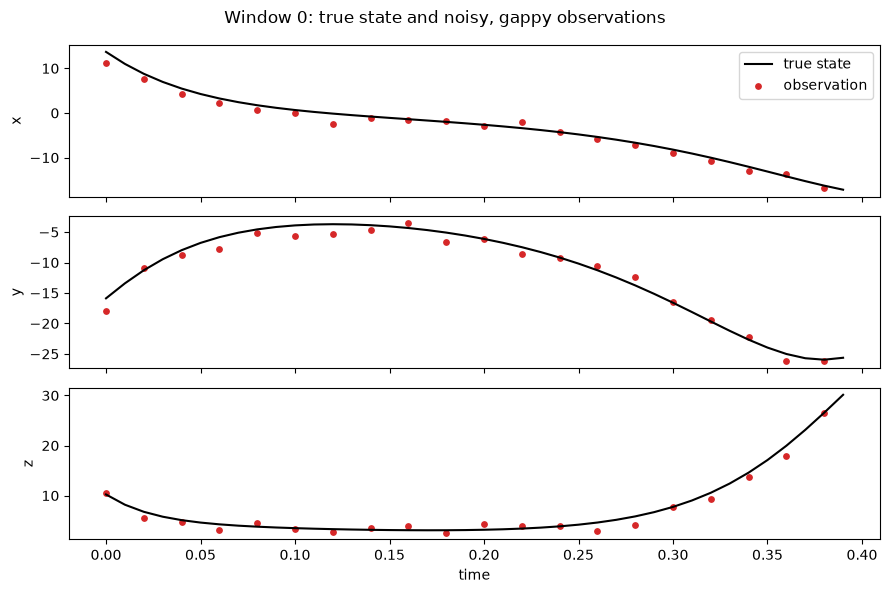

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(9, 6), sharex=True)
for i, (ax, name) in enumerate(zip(axes, ["x", "y", "z"])):
    ax.plot(ts, x_true[0, :, i], color="black", label="true state")
    ax.scatter(ts, y_obs[0, :, i], color="tab:red", s=15, label="observation")
    ax.set_ylabel(name)
axes[0].legend(loc="upper right")
axes[-1].set_xlabel("time")
fig.suptitle("Window 0: true state and noisy, gappy observations")
plt.tight_layout()
plt.show()

## 3. Stage 1 — known initial state, unknown $\theta$

With $u_0$ fixed to the truth the only control is $\theta$. The
strong-constraint cost has no background term (`alpha_bg=0`), and
`forward_fn` is the batched rollout with $\theta$ bound:

$$
\theta^* = \underset{\theta}{\arg\min}\; \sum_b \big\| m \odot (\varphi(u_0^b; \theta) - y^b) \big\|^2 .
$$

This is nonlinear least squares. We use Adam rather than a Gauss–Newton
or L-BFGS solver because it needs nothing but the gradient, its
per-coordinate normalisation copes with $\rho \approx 28$ and
$\beta \approx 2.7$ living on different scales, and the notebook is about
the gradient rather than the optimiser; `optimistix.LevenbergMarquardt`
on the residual vector would converge in far fewer iterations.

At the solution the cost cannot fall below the noise floor: with the true
parameters the misfit is just the noise, so
$U(\theta_{\text{true}}) \approx \frac{1}{2\sigma_{obs}^2} \cdot \sigma_{obs}^2 \cdot \#\{\text{observed}\}$,
which in the normalised units printed below is $\sigma_{obs}^2 \times$
(observed fraction) $= 0.5$. A fit that lands *below* the floor is fitting
noise; a fit far above it has not converged or is stuck.

In [5]:
def forward_fn(x0, ts, theta):
    return jax.vmap(lambda x0_i: prior(x0_i, ts, params=theta))(x0)


def cost_theta(theta, x0, ts, batch):
    return strong_variational_cost(
        x0,
        ts,
        batch,
        forward_fn=ft.partial(forward_fn, theta=theta),
        alpha_obs=1.0,
        alpha_bg=0.0,
        nan_to_num=True,
    )


theta_init = jnp.array([8.0, 24.0, 2.0])
opt = optax.adam(learning_rate=0.1)


@jax.jit
def step_theta(theta, opt_state):
    loss, grads = jax.value_and_grad(cost_theta)(theta, x0_true, ts, batch)
    updates, opt_state = opt.update(grads, opt_state, theta)
    return optax.apply_updates(theta, updates), opt_state, loss


theta = theta_init
opt_state = opt.init(theta)
history_theta, history_loss = [theta], []
for _ in range(300):
    theta, opt_state, loss = step_theta(theta, opt_state)
    history_theta.append(theta)
    history_loss.append(float(loss))
history_theta = jnp.stack(history_theta)

print("theta (init):", theta_init)
print("theta (fit): ", theta)
print("theta (true):", THETA_TRUE)
print(f"cost at fit={history_loss[-1]:.4f}, at truth={float(cost_theta(THETA_TRUE, x0_true, ts, batch)):.4f}")

theta (init): [ 8. 24.  2.]
theta (fit):  [ 9.9937    28.01535    2.6669064]
theta (true): [10.        28.         2.6666667]


cost at fit=0.5459, at truth=0.5469


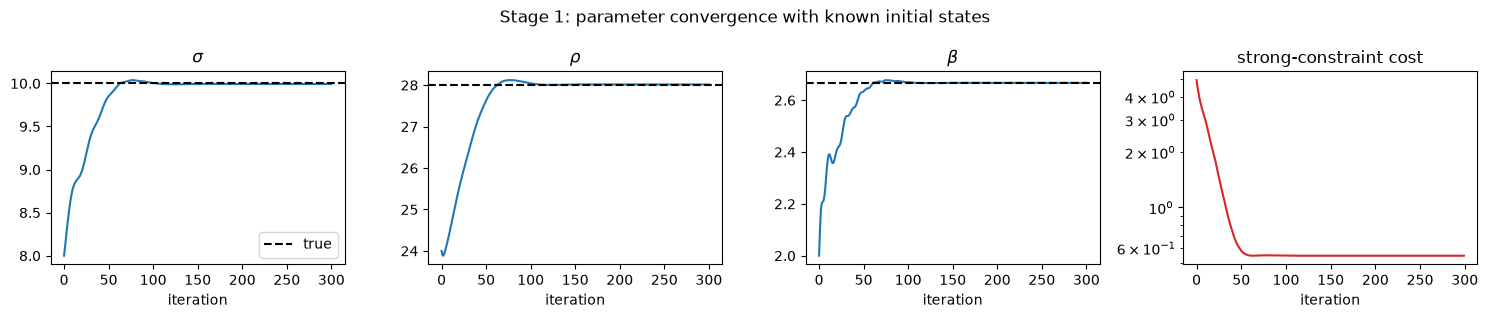

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2))
for i, (ax, name) in enumerate(zip(axes[:3], [r"$\sigma$", r"$\rho$", r"$\beta$"])):
    ax.plot(history_theta[:, i], color="tab:blue")
    ax.axhline(float(THETA_TRUE[i]), color="black", linestyle="--", label="true")
    ax.set_title(name)
    ax.set_xlabel("iteration")
axes[0].legend()
axes[3].semilogy(history_loss, color="tab:red")
axes[3].set_title("strong-constraint cost")
axes[3].set_xlabel("iteration")
fig.suptitle("Stage 1: parameter convergence with known initial states")
plt.tight_layout()
plt.show()

## 4. Identifiability — the cost along each parameter axis

Sweeping one parameter at a time (others held at the truth) shows how
sharply the data constrain each of them. Around its minimiser
$\hat\theta$ the realised cost is approximately quadratic,

$$
U(\theta) \approx U(\hat\theta) + \tfrac{1}{2}(\theta - \hat\theta)^\top
  \nabla^2 U(\hat\theta)\, (\theta - \hat\theta),
$$

and for a least-squares cost the Hessian splits into a Gauss–Newton part
built from first derivatives plus terms weighted by the residuals,

$$
\nabla^2 U = \underbrace{\frac{1}{\sigma_{obs}^2} \sum_{b,t} J_{b,t}^\top\, \mathrm{diag}(m_t)\, J_{b,t}}_{\mathcal{I}(\theta)}
  + \frac{1}{\sigma_{obs}^2}\sum_{b,t} \sum_i \big(m_t \odot r_{b,t}\big)_i\, \nabla^2_\theta (\varphi_t)_i ,
\qquad J_{b,t} = \frac{\partial \varphi_t(u_0^b; \theta)}{\partial \theta}.
$$

The first part is the Fisher information $\mathcal{I}$ of the experiment
(the expected curvature; the residual-weighted part averages to zero
under the noise model). Its inverse is the Cramér–Rao bound on the
covariance of *any* unbiased estimator, so the curvature of each profile
is not a property of the optimiser but of the data: a flat direction
means the observations cannot tell those parameter values apart, and no
amount of iteration will fix it. Two honest caveats about the plots: for
one noisy realisation the minimiser $\hat\theta$ sits near, not exactly
at, the truth (the score $\nabla U(\theta_{\text{true}})$ is small but not
zero), and each profile is a one-dimensional slice — parameter
correlations need the full matrix, which chapter
[13](../13_posterior_covariance.md) builds with `GaussNewtonHessian`.

The horizontal line is the noise floor
$\sigma_{obs}^2 \cdot$ (observed fraction) $= 0.5$. Try re-running section 2
with windows cut from a long on-attractor trajectory: the $\sigma$ curve
flattens to within a few percent of the floor, and gradient descent
wanders — which is exactly what happened in the first draft of this
notebook.

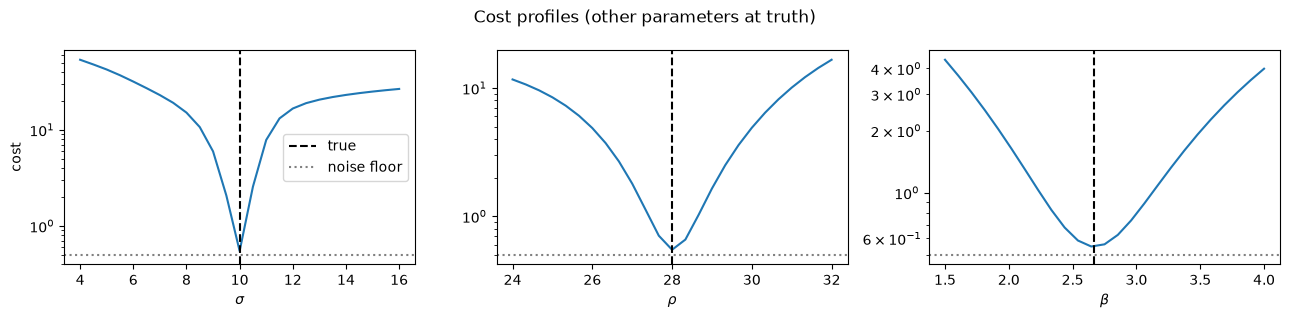

In [7]:
cost_jit = jax.jit(cost_theta)
sweeps = {
    r"$\sigma$": (0, jnp.linspace(4.0, 16.0, 25)),
    r"$\rho$": (1, jnp.linspace(24.0, 32.0, 25)),
    r"$\beta$": (2, jnp.linspace(1.5, 4.0, 25)),
}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
for ax, (name, (i, grid)) in zip(axes, sweeps.items()):
    profile = [float(cost_jit(THETA_TRUE.at[i].set(v), x0_true, ts, batch)) for v in grid]
    ax.plot(grid, profile, color="tab:blue")
    ax.axvline(float(THETA_TRUE[i]), color="black", linestyle="--", label="true")
    ax.axhline(SIGMA_OBS**2 * float(mask.mean()), color="gray", linestyle=":", label="noise floor")
    ax.set_xlabel(name)
    ax.set_yscale("log")
axes[0].set_ylabel("cost")
axes[0].legend()
fig.suptitle("Cost profiles (other parameters at truth)")
plt.tight_layout()
plt.show()

## 5. Stage 2 — joint estimation of $u_0$ and $\theta$

In practice the initial state is not known either. The control becomes the
PyTree $(u_0, \theta)$; the background $u_b$ is the noisy observation at
$t = 0$, and the background term keeps $u_0$ anchored to it while $\theta$
is far from the truth. Everything else is unchanged — the cost function is
indifferent to what `x0` and `params` are made of.

Two things are worth noticing about the joint problem.

- **It is the same problem as 4DVar.** Chapter [6](../06_strong_4dvar.md)
  minimises over $u_0$ with $\theta$ fixed; notebook
  [01](01_model_based_4dvar_L63.ipynb) does exactly that with
  `StrongFourDVar`. Adding $\theta$ to the control vector costs three more
  coordinates and nothing else, which is why "augmented state" is the
  standard DA route to parameter estimation.
- **The weights encode relative trust — after normalisation.**
  `strong_variational_cost` averages the misfit over $B \cdot T \cdot N$
  entries and the background over $B \cdot N$, so per *element* the
  observation weight is $\alpha_{obs} / T$ relative to $\alpha_{bg}$.
  Matching to the Gaussian sum cost gives
  $\sigma_b^2 / \sigma_{obs}^2 = \alpha_{obs} / (\alpha_{bg} T) = 1 / (0.1 \cdot 40) = 0.25$:
  with these settings the background counts as twice as precise as a
  single observation. The true background error here *is* one
  observation's worth of noise, so this over-trusts $u_b$ by a factor of
  four in variance — and the fit still moves $u_0$ a long way, because
  sixty observed values per window outweigh three background values.
  The exact Gaussian weighting would be $\alpha_{bg} = \alpha_{obs} / T$;
  try it, and then let the next notebook learn such weights instead of
  reasoning them out by hand.

In [8]:
def cost_joint(control, ts, batch, xb):
    return strong_variational_cost(
        control["x0"],
        ts,
        batch,
        forward_fn=ft.partial(forward_fn, theta=control["theta"]),
        background=xb,
        alpha_obs=1.0,
        alpha_bg=0.1,
        nan_to_num=True,
    )


x_b = jnp.nan_to_num(y_obs[:, 0])  # t = 0 is observed in every window
control = {"x0": x_b, "theta": theta_init}
opt_joint = optax.adam(learning_rate=0.05)


@jax.jit
def step_joint(control, opt_state):
    loss, grads = jax.value_and_grad(cost_joint)(control, ts, batch, x_b)
    updates, opt_state = opt_joint.update(grads, opt_state, control)
    return optax.apply_updates(control, updates), opt_state, loss


opt_state = opt_joint.init(control)
hist_theta_joint, hist_x0_err, hist_loss_joint = [control["theta"]], [], []
for _ in range(500):
    control, opt_state, loss = step_joint(control, opt_state)
    hist_theta_joint.append(control["theta"])
    hist_x0_err.append(float(jnp.sqrt(jnp.mean((control["x0"] - x0_true) ** 2))))
    hist_loss_joint.append(float(loss))
hist_theta_joint = jnp.stack(hist_theta_joint)

x0_rmse_bg = float(jnp.sqrt(jnp.mean((x_b - x0_true) ** 2)))
print("theta (fit): ", control["theta"])
print("theta (true):", THETA_TRUE)
print(f"initial-state RMSE: background={x0_rmse_bg:.3f} -> analysis={hist_x0_err[-1]:.3f}")

theta (fit):  [ 9.755503  28.085949   2.6493597]
theta (true): [10.        28.         2.6666667]
initial-state RMSE: background=1.198 -> analysis=0.568


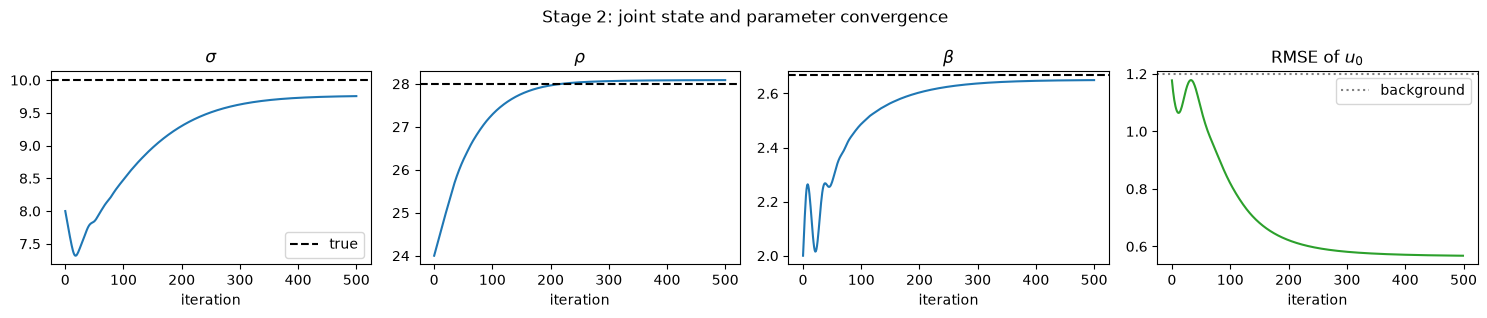

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2))
for i, (ax, name) in enumerate(zip(axes[:3], [r"$\sigma$", r"$\rho$", r"$\beta$"])):
    ax.plot(hist_theta_joint[:, i], color="tab:blue")
    ax.axhline(float(THETA_TRUE[i]), color="black", linestyle="--", label="true")
    ax.set_title(name)
    ax.set_xlabel("iteration")
axes[0].legend()
axes[3].plot(hist_x0_err, color="tab:green")
axes[3].axhline(x0_rmse_bg, color="gray", linestyle=":", label="background")
axes[3].set_title(r"RMSE of $u_0$")
axes[3].set_xlabel("iteration")
axes[3].legend()
fig.suptitle("Stage 2: joint state and parameter convergence")
plt.tight_layout()
plt.show()

The analysed trajectory — the rollout of the estimated $u_0$ with the
estimated $\theta$ — fills the gaps and denoises the observations. Because
the dynamics are a hard constraint, the analysis is by construction a
solution of the ODE: the observations can only choose *which* solution,
through $u_0$ and $\theta$, never bend it. That is what the strong
constraint buys (smooth, physically consistent fields between
observations) and what it costs (no way to absorb model error).

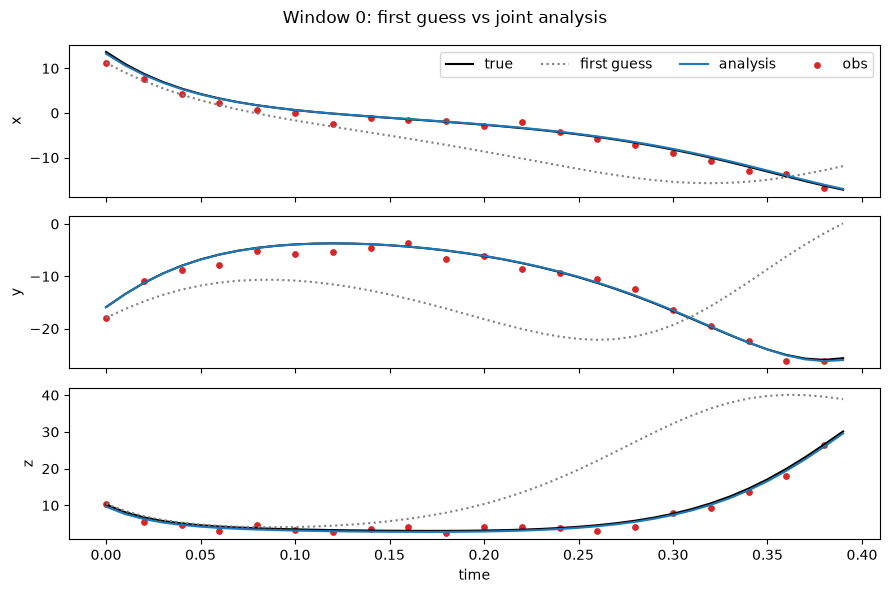

trajectory MSE: first guess=13.687, analysis=0.096


In [10]:
x_analysis = forward_fn(control["x0"], ts, control["theta"])
x_first_guess = forward_fn(x_b, ts, theta_init)

fig, axes = plt.subplots(3, 1, figsize=(9, 6), sharex=True)
for i, (ax, name) in enumerate(zip(axes, ["x", "y", "z"])):
    ax.plot(ts, x_true[0, :, i], color="black", label="true")
    ax.plot(ts, x_first_guess[0, :, i], color="gray", linestyle=":", label="first guess")
    ax.plot(ts, x_analysis[0, :, i], color="tab:blue", label="analysis")
    ax.scatter(ts, y_obs[0, :, i], color="tab:red", s=15, label="obs")
    ax.set_ylabel(name)
axes[0].legend(loc="upper right", ncol=4)
axes[-1].set_xlabel("time")
fig.suptitle("Window 0: first guess vs joint analysis")
plt.tight_layout()
plt.show()

mse_fg = float(jnp.mean((x_first_guess - x_true) ** 2))
mse_an = float(jnp.mean((x_analysis - x_true) ** 2))
print(f"trajectory MSE: first guess={mse_fg:.3f}, analysis={mse_an:.3f}")

## 6. Weak-constraint variant — one-step increments

When a *densely* sampled trajectory is available, the
[`DynIncrements`](xref:api#vardax.DynIncrements) prior offers a cheaper route. Its
loss is the sum of one-step residuals,

$$
R(u; \theta) = \sum_t \big\| u_{t+1} - \varphi_{\Delta t}(u_t; \theta) \big\|^2 ,
$$

so every step is an independent short solve (vectorised with `vmap`) and
no long rollout — or initial-state estimate — is needed. This is the
model-error residual of weak-constraint 4DVar (chapter
[7](../07_weak_4dvar.md)) with the states held fixed: each term asks how
far the observed state at $t+1$ is from where the model would have put it,
and $\theta$ is chosen to make those increments as small as possible. The
gradient only ever passes through one step of the solver, so this cost is
smooth even for windows far longer than the Lyapunov time.

The price is that noise in the trajectory enters the residual on *both*
sides. Writing $u_t = \bar u_t + \varepsilon_t$ for the true state plus
noise and linearising the flow map,

$$
u_{t+1} - \varphi_{\Delta t}(u_t; \theta)
  \approx \big(\bar u_{t+1} - \varphi_{\Delta t}(\bar u_t; \theta)\big)
        + \varepsilon_{t+1} - \frac{\partial \varphi_{\Delta t}}{\partial u}\,\varepsilon_t ,
$$

and the last term depends on $\theta$ through the Jacobian. Least squares
with noise in the regressors is the errors-in-variables problem: the
estimator is exact on clean data and increasingly biased as the noise
grows, in contrast with the strong-constraint fit where noise sits only in
the target and averages out. Fitting $\theta$ to dense trajectories at
increasing noise levels shows this directly, and it is why the
strong-constraint formulation above is preferred for sparse or noisy
data.

In [11]:
inc_prior = DynIncrements(model=lorenz63_rhs)


def cost_increments(theta, x_traj, ts):
    return jax.vmap(lambda x_b: inc_prior.loss(x_b, ts, params=theta))(x_traj).sum()


opt_inc = optax.adam(learning_rate=0.1)


@jax.jit
def step_inc(theta, opt_state, x_traj):
    loss, grads = jax.value_and_grad(cost_increments)(theta, x_traj, ts)
    updates, opt_state = opt_inc.update(grads, opt_state, theta)
    return optax.apply_updates(theta, updates), opt_state, loss


noise_levels = [0.0, 0.1, 0.3, 1.0]
theta_by_noise = []
for level in noise_levels:
    x_dense = x_true + level * jax.random.normal(k_noise, x_true.shape)
    theta_inc, opt_state = theta_init, opt_inc.init(theta_init)
    for _ in range(300):
        theta_inc, opt_state, _ = step_inc(theta_inc, opt_state, x_dense)
    theta_by_noise.append(theta_inc)
    print(f"noise sigma={level:.1f}: theta={theta_inc}")
theta_by_noise = jnp.stack(theta_by_noise)
print(f"true:            theta={THETA_TRUE}")

noise sigma=0.0: theta=[10.000011  28.000076   2.6666625]


noise sigma=0.1: theta=[ 9.978331  28.02465    2.6730726]


noise sigma=0.3: theta=[10.020732  28.070986   2.6935024]


noise sigma=1.0: theta=[11.0484915 28.194181   2.844365 ]
true:            theta=[10.        28.         2.6666667]


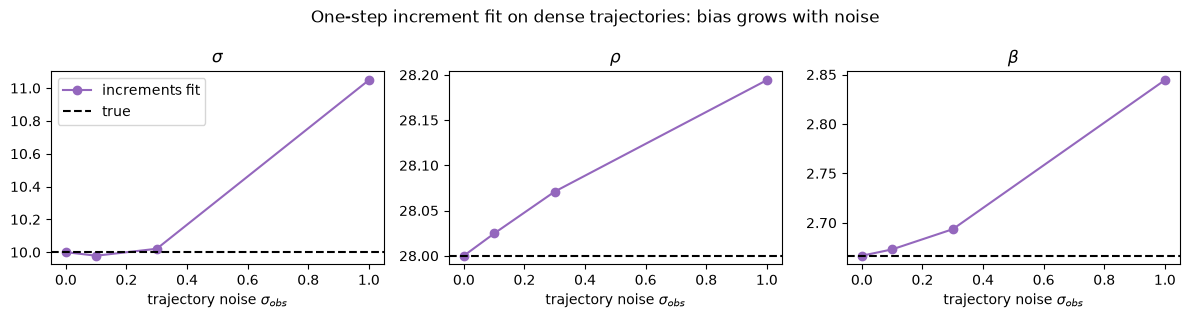

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for i, (ax, name) in enumerate(zip(axes, [r"$\sigma$", r"$\rho$", r"$\beta$"])):
    ax.plot(noise_levels, theta_by_noise[:, i], marker="o", color="tab:purple", label="increments fit")
    ax.axhline(float(THETA_TRUE[i]), color="black", linestyle="--", label="true")
    ax.set_title(name)
    ax.set_xlabel(r"trajectory noise $\sigma_{obs}$")
axes[0].legend()
fig.suptitle("One-step increment fit on dense trajectories: bias grows with noise")
plt.tight_layout()
plt.show()

## Summary

- Parameter estimation is 4DVar with an augmented control vector: the
  MAP estimate of $(u_0, \theta)$ minimises the same strong-constraint
  cost, with the weights set by the error variances.
- `DynTrajectory` + `strong_variational_cost` turn it into ordinary
  gradient descent: $\theta$ rides along as the diffrax `args`, and
  `jax.grad` differentiates through the ODE solve with a checkpointed
  adjoint.
- Identifiability is a property of the *data*, not the optimiser. The
  curvature of the cost at the truth is the Fisher information; sweep it
  before trusting a fit, and design the experiment (here: off-attractor
  transients) so the flat directions disappear.
- `DynIncrements` gives the one-step (weak-constraint) residual for
  fitting $\theta$ to dense trajectories — cheap and smooth, but an
  errors-in-variables estimator that noise biases.

Where this leads: the mfourdvar notes continue with *hybrid* models,
$f = f_{\text{dyn}}(u; \theta) + g_\phi(u)$ where a neural network
$g_\phi$ absorbs missing physics, and with surrogate models where
$f = g_\phi$ entirely (neural ODEs). Both are the same gradient descent
with a larger `params` PyTree. See chapter
[19](../19_physical_models.md) for the prior design and chapter
[12](../12_adjoint_methods.md) for choosing the adjoint on long windows.